# Comparação das Heurísticas Construtivas: AisleBased vs OrderBased

**Objetivo:** Comparar, a partir dos resultados em Java, as heurísticas construtivas
*AisleBased* e *OrderBased* (versão agregada das variantes de cada uma) em termos de
qualidade de solução (gap em relação à melhor solução conhecida — MSC), tempo de execução,
unidades selecionadas e corredores visitados, nos datasets A, B e X ($50$ instâncias no total).

## Tabelas e Figuras Geradas

| Identificador | Título / Conteúdo | Colunas e Linhas no Texto | Objetivo |
|:---:|---|:---:|---|
| **T1** (`tab_1`) | Gap e tempo por dataset e algoritmo | $8$ colunas $\times 8$ linhas | Resumir a qualidade e o tempo de cada construtiva. Mostra a cauda do AisleBased em A e o tempo superior do OrderBased |
| **T2** (`tab_2`) | Comparação pareada (gap e razão de tempo) | $5$ colunas $\times 4$ linhas | Mostrar que a dominância do AisleBased é consistente instância a instância e a razão de tempo entre os métodos |
| **T3a** (`tab_3` / `tab_3a`) | Unidades e corredores por algoritmo | $6$ colunas $\times 8$ linhas | Valores de unidades e corredores (mediana e média) por dataset e algoritmo |
| **T3b** (`tab_3b`) | Razões e dominância em unidades e corredores | $4$ colunas $\times 4$ linhas | Evidenciar a desproporção: OrderBased coleta $1,8\times$ a $3,4\times$ mais unidades, mas visita $20\times$ a $53\times$ mais corredores |
| **T4** (`tab_4`) | Piores instâncias do AisleBased em A | $6$ colunas $\times 5$ linhas | Caracterizar a cauda do AisleBased e mostrar se o excesso está em corredores ou em unidades. Liga ao capítulo do ILS-VND |
| **F1** (`fig_1`) | Distribuição do gap | $6,3 \times 3,8$ in | Boxplot com pontos individuais. Cores padrão (tab:blue e tab:orange) por algoritmo. Eixo $y$ em escala symlog com divisão uniforme por tick ($0, 1, 10, 100$) |
| **F2** (`fig_2`) | Unidades e corredores (dois painéis) | $6,3 \times 3,4$ in | Dois painéis logarítmicos evidenciando unidades e corredores com diferenciação por cores padrão e marcadores |
| **A1** (`tab_A1`) | Decomposição em relação à MSC (Apêndice) | $5$ colunas $\times 6$ linhas | Diferença relativa de unidades e corredores em relação à MSC e fração de unidades sobre o UB |
| **A2** (`tab_A2`) | Resultados por instância (Apêndice) | $7$ colunas $\times 50$ linhas | Tabela completa em `longtable` com gap, unidades e corredores de cada instância |
| — | Números-chave (`numeros_chave.csv`) | — | Resumo dos números citados ao longo do texto da dissertação |

## Convenções do Estudo

- **Unidade estatística:** instância. As réplicas servem exclusivamente para estabilizar as medições de tempo de execução, visto que os algoritmos construtivos são determinísticos.
- **Métricas agregadas por instância:** Gap, unidades e corredores correspondem à média aritmética das réplicas; o tempo de execução por instância corresponde à mediana das réplicas, reportado em segundos.
- **Convenção de Gap (%):** $\text{Gap (\%)} = \frac{\text{MSC} - \text{obtido}}{\text{MSC}} \times 100$, calculado primeiro por execução e depois agregado. Valores menores indicam soluções melhores (maximização).
- **Critério de empate:** Duas soluções são consideradas empatadas se $|\Delta| \le 10^{-9}$.
- **Formatação para LaTeX (abnTeX2):** Tabelas em estilo `booktabs` (sem linhas verticais), fonte `\small`, vírgula decimal em todas as tabelas e símbolos fora do ASCII em modo matemático.
- **Legendas e descrição de colunas:** Todas as tabelas contam com legenda detalhada de cada uma de suas colunas, apresentada na célula Markdown, no terminal de saída e como comentários no arquivo LaTeX (`.tex`).
- **Esquema de Cores das Figuras:** Cores padrão do matplotlib (`tab:blue` para *AisleBased* e `tab:orange` para *OrderBased*) para diferenciação visual inequívoca das construtivas.


## 1. Configuração

In [1]:
import sys
import os
from pathlib import Path

# ── Localização da raiz do repositório ───────────────────────────────────────
_candidate = Path.cwd()
ROOT = None
for _p in [_candidate] + list(_candidate.parents):
    if (_p / "notebooks" / "utils" / "__init__.py").exists():
        ROOT = _p
        break
if ROOT is None:
    raise RuntimeError("Raiz do repositório não encontrada (notebooks/utils/__init__.py ausente).")

# ── Caminhos principais ───────────────────────────────────────────────────────
RESULTS_BASE   = ROOT / "project" / "results"
DATASETS_BASE  = ROOT / "datasets"
BEST_SOL_BASE  = ROOT / "best_solutions"
BEST_OBJ_CSV   = BEST_SOL_BASE / "best_objectives.csv"
VALIDATOR_DIR  = ROOT / "project" / "validator"
UTILS_DIR      = ROOT / "notebooks" / "utils"
OUTPUT_DIR     = ROOT / "notebooks" / "experimentos" / "output" / "construtivas_final"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Adiciona os diretórios ao sys.path
for _d in [str(ROOT / "notebooks"), str(VALIDATOR_DIR), str(ROOT)]:
    if _d not in sys.path:
        sys.path.insert(0, _d)

# ── Constantes ────────────────────────────────────────────────────────────────
TOL         = 1e-9          # tolerância para empates em comparações
SEED        = 42            # semente aleatória global
DATASETS    = ["a", "b", "x"]
DS_LABELS   = {"a": "A", "b": "B", "x": "X"}
ALGOS       = ["aisle_based", "order_based"]
ALGO_LABELS = {"aisle_based": "AisleBased", "order_based": "OrderBased"}

# ── Estilo de figuras ─────────────────────────────────────────────────────────
FIG_W      = 6.3           # largura útil da página em polegadas
FIG_H1     = 3.8           # altura fig_1
FIG_H2     = 3.4           # altura fig_2
FONT_MIN   = 9             # fonte mínima em pt

# Cores padrão do matplotlib (tab:blue e tab:orange) para diferenciação por algoritmo
COLORS = {
    "aisle_based": "tab:blue",     # azul padrão (C0)
    "order_based": "tab:orange",   # laranja padrão (C1)
}
MARKERS = {
    "aisle_based": "o",            # círculo
    "order_based": "s",            # quadrado
}

# ── Configuração global de matplotlib ────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
plt.rcParams.update({
    "font.size":        FONT_MIN,
    "axes.titlesize":   FONT_MIN,
    "axes.labelsize":   FONT_MIN,
    "xtick.labelsize":  FONT_MIN,
    "ytick.labelsize":  FONT_MIN,
    "legend.fontsize":  FONT_MIN,
    "figure.dpi":       150,
    "savefig.dpi":      300,
    "pdf.fonttype":     42,
    "ps.fonttype":      42,
})

print("ROOT          :", ROOT)
print("RESULTS_BASE  :", RESULTS_BASE)
print("DATASETS_BASE :", DATASETS_BASE)
print("BEST_OBJ_CSV  :", BEST_OBJ_CSV)
print("VALIDATOR_DIR :", VALIDATOR_DIR)
print("OUTPUT_DIR    :", OUTPUT_DIR)


ROOT          : /home/vinicius/Documents/CEFET/TCC/pfc2
RESULTS_BASE  : /home/vinicius/Documents/CEFET/TCC/pfc2/project/results
DATASETS_BASE : /home/vinicius/Documents/CEFET/TCC/pfc2/datasets
BEST_OBJ_CSV  : /home/vinicius/Documents/CEFET/TCC/pfc2/best_solutions/best_objectives.csv
VALIDATOR_DIR : /home/vinicius/Documents/CEFET/TCC/pfc2/project/validator
OUTPUT_DIR    : /home/vinicius/Documents/CEFET/TCC/pfc2/notebooks/experimentos/output/construtivas_final


## 2. Utilitários

In [2]:
import re
import io
import csv
import tempfile
import numpy as np
import pandas as pd
from scipy import stats

# ── Formatador numérico com vírgula decimal ───────────────────────────────────
def fmt(value, decimals=2):
    """Formata número com vírgula como separador decimal."""
    if pd.isna(value):
        return "--"
    if isinstance(value, (int, np.integer)):
        return f"{int(value)}"
    fmt_str = f"{value:.{decimals}f}"
    return fmt_str.replace(".", ",")

# ── Escape LaTeX ──────────────────────────────────────────────────────────────
def tex_escape(text, raw=False):
    """Escapa texto para LaTeX. Se raw=True, retorna sem escape (modo matemático)."""
    if raw:
        return str(text)
    s = str(text)
    s = s.replace("\\", r"\textbackslash{}")
    s = s.replace("&",  r"\&")
    s = s.replace("%",  r"\%")
    s = s.replace("#",  r"\#")
    s = s.replace("_",  r"\_")
    s = s.replace("{",  r"\{")
    s = s.replace("}",  r"\}")
    s = s.replace("~",  r"\textasciitilde{}")
    s = s.replace("^",  r"\textasciicircum{}")
    return s

# ── Escritor de tabular booktabs ──────────────────────────────────────────────
def make_tabular(header_rows, data_rows, col_align, raw_cols=None):
    if raw_cols is None:
        raw_cols = set()

    lines = []
    lines.append(r"\small")
    lines.append(r"\begin{tabular}{" + col_align + "}")
    lines.append(r"\toprule")

    for h_row in header_rows:
        cells_tex = []
        for j, cell in enumerate(h_row):
            if isinstance(cell, tuple):
                txt, is_raw = cell
            else:
                txt, is_raw = cell, (j in raw_cols)
            cells_tex.append(tex_escape(txt, raw=is_raw))
        lines.append(" & ".join(cells_tex) + r" \\")
    lines.append(r"\midrule")

    for row in data_rows:
        cells_tex = []
        for j, cell in enumerate(row):
            if isinstance(cell, tuple):
                txt, is_raw = cell
            else:
                txt, is_raw = cell, (j in raw_cols)
            cells_tex.append(tex_escape(str(txt), raw=is_raw))
        lines.append(" & ".join(cells_tex) + r" \\")

    lines.append(r"\bottomrule")
    lines.append(r"\end{tabular}")
    return "\n".join(lines)

# ── Gravador CSV + .tex ───────────────────────────────────────────────────────
def salvar_tabela(nome, df_csv, tex_str, output_dir=OUTPUT_DIR):
    csv_path = output_dir / f"{nome}.csv"
    tex_path = output_dir / f"{nome}.tex"
    df_csv.to_csv(csv_path, index=False)
    tex_path.write_text(tex_str, encoding="utf-8")
    return csv_path, tex_path

# ── Teste de sinais exato bilateral ──────────────────────────────────────────
def teste_sinais(diffs):
    diffs = np.asarray(diffs, dtype=float)
    diffs_nonzero = diffs[np.abs(diffs) > TOL]
    n = len(diffs_nonzero)
    if n == 0:
        return np.nan
    k = int(np.sum(diffs_nonzero > 0))
    result = stats.binomtest(k, n, p=0.5, alternative="two-sided")
    return result.pvalue

# ── Resumo pareado ────────────────────────────────────────────────────────────
def resumo_pareado(vals_a, vals_b, maior_e_melhor_a=False):
    a = np.asarray(vals_a, dtype=float)
    b = np.asarray(vals_b, dtype=float)
    diffs = a - b
    if maior_e_melhor_a:
        wins   = int(np.sum(diffs >  TOL))
        losses = int(np.sum(diffs < -TOL))
    else:
        wins   = int(np.sum(diffs < -TOL))
        losses = int(np.sum(diffs >  TOL))
    ties = len(diffs) - wins - losses
    return wins, ties, losses, diffs

# ── Verificação estrutural de .tex ────────────────────────────────────────────
def verificar_tex(tex_str, nome=""):
    erros = []
    if re.search(r'\\\\(begin|end|toprule|midrule|bottomrule|small)', tex_str):
        erros.append("barras duplicadas em comandos estruturais")
    begins = re.findall(r'\\begin\{(\w+)\}', tex_str)
    ends   = re.findall(r'\\end\{(\w+)\}', tex_str)
    if sorted(begins) != sorted(ends):
        erros.append(f"begin/end desbalanceados: {begins} vs {ends}")
    tex_lines = [l for l in tex_str.split("\n") if l.strip().endswith(r"\\") and "&" in l]
    counts = [l.count("&") for l in tex_lines]
    if len(set(counts)) > 1:
        erros.append(f"número de & inconsistente por linha: {set(counts)}")
    return erros

# ─── Auto-teste ───────────────────────────────────────────────────────────────
with tempfile.TemporaryDirectory() as _tmpdir:
    _hdr = [["Dataset", "Algoritmo", "Mediana", "Média"]]
    _dat = [
        ["A", "AisleBased", fmt(1.23), fmt(2.34)],
        ["B", "OrderBased", fmt(5.67), fmt(6.78)],
    ]
    _tex = make_tabular(_hdr, _dat, "llrr")
    _erros = verificar_tex(_tex, "auto-teste")
    if _erros:
        print("AUTO-TESTE FALHOU:", _erros)
    else:
        print("Auto-teste dos utilitários: ok")
    assert "1,23" in _tex and "2,34" in _tex, "vírgula decimal ausente"
    print("Vírgula decimal: ok")


Auto-teste dos utilitários: ok
Vírgula decimal: ok


## 3. Carga dos Resultados

In [3]:
from utils.resultados import carregar_resultados

df_aisle = carregar_resultados("aisle_based", RESULTS_BASE)
df_aisle["algo_id"] = "aisle_based"

df_order = carregar_resultados("order_based", RESULTS_BASE)
df_order["algo_id"] = "order_based"

df_raw = pd.concat([df_aisle, df_order], ignore_index=True)

print("Colunas encontradas:", list(df_raw.columns))
_time_cols = [c for c in df_raw.columns if "time" in c.lower()]
print(f"Coluna de tempo identificada: '{_time_cols[0]}'" if _time_cols else "Coluna de tempo NÃO encontrada!")

print("""
exec_time:
  - Mede o tempo de execução reportado pelo solver Java (em segundos).
  - Inclui a fase de processamento do algoritmo sobre a instância lida.
  - A unidade verificada é segundos.
""")

print("Número de execuções por algoritmo e dataset:")
_ct = df_raw.groupby(["algo_id", "dataset"]).size().unstack(fill_value=0)
_ct.columns = [DS_LABELS.get(c, c) for c in _ct.columns]
_ct.index = [ALGO_LABELS.get(i, i) for i in _ct.index]
display(_ct)


Colunas encontradas: ['algo_id', 'run_id', 'seed', 'status', 'objective', 'items', 'aisles', 'exec_time', 'dataset', 'instance', 'result_dir']
Coluna de tempo identificada: 'exec_time'

exec_time:
  - Mede o tempo de execução reportado pelo solver Java (em segundos).
  - Inclui a fase de processamento do algoritmo sobre a instância lida.
  - A unidade verificada é segundos.

Número de execuções por algoritmo e dataset:


,A,B,X
AisleBased,600,450,450
OrderBased,600,450,450


## 4. Viabilidade

In [4]:
_infeasible = df_raw[df_raw["status"] != "feasible"].copy()

if len(_infeasible) == 0:
    print(f"Nenhuma execução inviável (todas as {len(df_raw)} execuções têm status 'feasible').")
else:
    print(f"ATENÇÃO: {len(_infeasible)} execução(ões) inviável(is) encontrada(s):")
    display(_infeasible[["dataset", "instance", "algo_id", "status"]].drop_duplicates())

df_viable = df_raw[df_raw["status"] == "feasible"].copy()
print(f"Execuções viáveis mantidas para análise: {len(df_viable)}")


Nenhuma execução inviável (todas as 3000 execuções têm status 'feasible').
Execuções viáveis mantidas para análise: 3000


## 5. Preparo dos Dados por Instância

In [5]:
import sys as _sys
_sys.path.insert(0, str(VALIDATOR_DIR))
from validator import parse_instance, parse_solution
# ── 5a. Carregar MSC (Melhor Solução Conhecida) ──────────────────────────────
_msc_raw = pd.read_csv(BEST_OBJ_CSV)
_msc_raw["instance"] = _msc_raw["instance"].str.strip().str.replace("\r", "", regex=False)
_msc_raw["instance_key"] = _msc_raw["instance"].str.replace(".txt", "", regex=False)
_msc_raw["dataset"]      = _msc_raw["dataset"].str.strip()
msc_dict = {
    (row["dataset"], row["instance_key"]): row["best_objective"]
    for _, row in _msc_raw.iterrows()
}
print(f"MSC carregadas: {len(msc_dict)} instâncias registradas em best_objectives.csv")
# ── 5b. Calcular gap (%) por execução individual ─────────────────────────────
def calc_gap(obj, msc):
    if pd.isna(msc) or msc == 0:
        return np.nan
    return (msc - obj) / msc * 100.0
df_viable = df_viable.copy()
df_viable["msc"] = df_viable.apply(
    lambda r: msc_dict.get((r["dataset"], r["instance"]), np.nan), axis=1
)
df_viable["gap"] = df_viable.apply(
    lambda r: calc_gap(r["objective"], r["msc"]), axis=1
)
# ── 5c. Agregar por instância e algoritmo ────────────────────────────────────
agg_dict = {
    "gap":       "mean",
    "objective": "mean",
    "items":     "mean",
    "aisles":    "mean",
    "exec_time": "median",
    "msc":       "first",
}
df_inst = (
    df_viable
    .groupby(["dataset", "instance", "algo_id"])
    .agg(agg_dict)
    .reset_index()
)
df_inst.rename(columns={"exec_time": "tempo_s"}, inplace=True)
# ── 5d. Extrair informações das instâncias via parse_instance ────────────────
_inst_info = {}
for ds in DATASETS:
    for inst_file in sorted((DATASETS_BASE / ds).glob("*.txt")):
        key = (ds, inst_file.stem)
        try:
            info = parse_instance(inst_file)
            _inst_info[key] = {
                "lb": info["lb"],
                "ub": info["ub"],
                "n_orders": info["n_orders"],
                "n_items":  info["n_items"],
                "n_aisles_inst": info["n_aisles"],
            }
        except Exception as e:
            print(f"AVISO: falha ao analisar instância {inst_file}: {e}")
            _inst_info[key] = {"lb": np.nan, "ub": np.nan,
                               "n_orders": np.nan, "n_items": np.nan,
                               "n_aisles_inst": np.nan}
for col in ["lb", "ub", "n_orders", "n_items", "n_aisles_inst"]:
    df_inst[col] = df_inst.apply(
        lambda r, c=col: _inst_info.get((r["dataset"], r["instance"]), {}).get(c, np.nan), axis=1
    )
# ── 5e. Validar soluções MSC com o validator ─────────────────────────────────
_msc_info = {}
for ds in DATASETS:
    _bsd = BEST_SOL_BASE / ds
    if not _bsd.exists():
        continue
    for sol_file in sorted(_bsd.glob("*.txt")):
        key = (ds, sol_file.stem)
        try:
            _inst_path = DATASETS_BASE / ds / f"{sol_file.stem}.txt"
            _sol_parsed = parse_solution(sol_file)
            _inst_parsed = parse_instance(_inst_path)
            _n_aisles = len(set(_sol_parsed["visited_aisles"]))
            _n_items  = sum(
                _inst_parsed["order_units"][o]
                for o in set(_sol_parsed["selected_orders"])
            )
            _obj = _n_items / _n_aisles if _n_aisles > 0 else np.nan
            _msc_info[key] = {
                "msc_items":  _n_items,
                "msc_aisles": _n_aisles,
                "msc_obj":    _obj,
            }
        except Exception as e:
            print(f"AVISO: falha na validação MSC para {sol_file}: {e}")
            _msc_info[key] = {"msc_items": np.nan, "msc_aisles": np.nan, "msc_obj": np.nan}
for col in ["msc_items", "msc_aisles", "msc_obj"]:
    df_inst[col] = df_inst.apply(
        lambda r, c=col: _msc_info.get((r["dataset"], r["instance"]), {}).get(c, np.nan), axis=1
    )
# ── 5f. Verificações do conjunto agregado por instância ──────────────────────
_n_per_algo = df_inst.groupby("algo_id")["instance"].count()
print("\nInstâncias por algoritmo:")
for a, n in _n_per_algo.items():
    status = "ok" if n == 50 else f"AVISO: esperado 50, obtido {n}"
    print(f"  {ALGO_LABELS[a]}: {n} — {status}")
_n_per_ds_algo = df_inst.groupby(["dataset", "algo_id"])["instance"].count().unstack()
_n_per_ds_algo.index = [DS_LABELS.get(i, i) for i in _n_per_ds_algo.index]
_n_per_ds_algo.columns = [ALGO_LABELS.get(c, c) for c in _n_per_ds_algo.columns]
print("\nInstâncias por dataset e algoritmo:")
display(_n_per_ds_algo)
_missing = df_inst[["gap", "objective", "items", "aisles", "tempo_s"]].isna().sum()
_missing_nz = _missing[_missing > 0]
print("\nValores ausentes nas métricas principais:")
if len(_missing_nz) == 0:
    print("  Nenhum valor ausente encontrado.")
else:
    display(_missing_nz)
_neg_gaps = df_inst[df_inst["gap"] < -TOL]
print(f"\nContagem de gaps negativos: {len(_neg_gaps)}")
if len(_neg_gaps) > 0:
    print("  Achado: Instâncias onde o algoritmo superou a MSC registrada:")
    display(_neg_gaps[["dataset", "instance", "algo_id", "gap", "objective", "msc"]])
else:
    print("  Nenhum gap negativo encontrado (todas as soluções >= 0% em relação à MSC).")
print(f"\nTotal de linhas na tabela única por instância: {len(df_inst)} (50 instâncias × 2 algoritmos = 100)")


MSC carregadas: 50 instâncias registradas em best_objectives.csv

Instâncias por algoritmo:
  AisleBased: 50 — ok
  OrderBased: 50 — ok

Instâncias por dataset e algoritmo:


,AisleBased,OrderBased
A,20,20
B,15,15
X,15,15



Valores ausentes nas métricas principais:
  Nenhum valor ausente encontrado.

Contagem de gaps negativos: 0
  Nenhum gap negativo encontrado (todas as soluções >= 0% em relação à MSC).

Total de linhas na tabela única por instância: 100 (50 instâncias × 2 algoritmos = 100)


## 6. Tabela 1: Gap e Tempo por Dataset e Algoritmo

**Objetivo:** Resumir a qualidade das soluções (gap relativo percentual em relação à MSC) e o tempo computacional mediano despendido por cada construtiva nos datasets A, B, X e Geral.

### Legenda e Descrição das Colunas
* **Dataset:** Subconjunto de instâncias avaliado (`A` com 20 instâncias, `B` com 15 instâncias, `X` com 15 instâncias, ou `Geral` consolidando todas as 50 instâncias).
* **Algoritmo:** Heurística construtiva avaliada (`AisleBased` ou `OrderBased`).
* **Mediana:** Mediana do gap relativo percentual (%) entre as instâncias do dataset. Representa o patamar central típico de qualidade, imune a valores extremos (outliers).
* **Média (DP):** Média aritmética amostral do gap relativo (%) acompanhada do Desvio Padrão amostral ($DP$) entre parênteses. A divergência entre média e mediana evidencia assimetria positiva puxada por cauda pesada de piores casos.
* **P90:** 90º percentil da distribuição do gap relativo (%). Limite de gap abaixo do qual se encontram 90% das instâncias (comportamento sob estresse / cauda superior).
* **Máx.:** Valor máximo de gap relativo (%) observado em uma instância do dataset (pior resultado pontual).
* **Gap ≤ 1% ($n$/$N$):** Quantidade e proporção de instâncias em que o algoritmo atingiu gap relativo menor ou igual a 1,0% em relação à melhor solução conhecida ($n$ instâncias de um universo de $N$). Mensura a capacidade da heurística em atingir soluções quase ótimas sem busca local.
* **Tempo (s):** Mediana dos tempos de execução por instância em segundos ($s$). Mede o esforço computacional despendido pelo algoritmo.


In [6]:
def resumo_gap_dataset(df, ds_filter=None):
    _df = df if ds_filter is None else df[df["dataset"].isin(ds_filter)]
    rows = []
    for algo in ALGOS:
        _sub_gap = _df[_df["algo_id"] == algo]["gap"].dropna()
        _sub_tempo = _df[_df["algo_id"] == algo]["tempo_s"].dropna()
        rows.append({
            "algo_id": algo,
            "mediana": _sub_gap.median(),
            "media":   _sub_gap.mean(),
            "dp":      _sub_gap.std(ddof=1),
            "p90":     _sub_gap.quantile(0.90),
            "maximo":  _sub_gap.max(),
            "n_le1":   int((_sub_gap <= 1.0 + TOL).sum()),
            "N":       len(_sub_gap),
            "tempo_mediana": _sub_tempo.median(),
        })
    return rows

HEADER_1 = [["Dataset", "Algoritmo", "Mediana", r"Média (DP)",
              "P90", r"Máx.", (r"Gap $\leq$ 1\% ($n$/$N$)", True), "Tempo (s)"]]

tab1_rows_csv = []
tab1_rows_tex = []

for ds in DATASETS + [None]:
    ds_label = DS_LABELS.get(ds, "Geral") if ds else "Geral"
    ds_filter = [ds] if ds else DATASETS
    stats_rows = resumo_gap_dataset(df_inst, ds_filter)

    for i, row in enumerate(stats_rows):
        albl = ALGO_LABELS[row["algo_id"]]
        tab1_rows_csv.append([
            ds_label, albl,
            row["mediana"], row["media"], row["dp"],
            row["p90"], row["maximo"],
            f"{row['n_le1']}/{row['N']}",
            row["tempo_mediana"]
        ])
        tab1_rows_tex.append([
            ds_label if i == 0 else "",
            albl,
            fmt(row["mediana"]),
            f"{fmt(row['media'])} ({fmt(row['dp'])})",
            fmt(row["p90"]),
            fmt(row["maximo"]),
            (f"{row['n_le1']}/{row['N']}", False),
            fmt(row["tempo_mediana"]),
        ])

df_tab1 = pd.DataFrame(tab1_rows_csv, columns=[
    "Dataset", "Algoritmo", "Mediana", "Media", "DP", "P90", "Max", "Gap_le1_nN", "Tempo_s"
])

tex1 = make_tabular(
    HEADER_1,
    tab1_rows_tex,
    "llrrrrrr",
    raw_cols={6}
)

LEGENDA_TAB1_TEX = """% Legenda e Descrição das Colunas:
% - Dataset: Subconjunto de instâncias avaliado (A, B, X, Geral).
% - Algoritmo: Heurística construtiva avaliada (AisleBased ou OrderBased).
% - Mediana: Mediana do gap relativo percentual (%) em relação à MSC.
% - Média (DP): Média aritmética amostral e Desvio Padrão amostral do gap relativo (%).
% - P90: 90º percentil do gap relativo (%).
% - Máx.: Valor máximo do gap relativo (%) observado no dataset.
% - Gap <= 1% (n/N): Proporção de instâncias com gap relativo <= 1,0% em relação à MSC.
% - Tempo (s): Mediana do tempo de execução por instância em segundos."""

tex1_completo = tex1 + "\n\n" + LEGENDA_TAB1_TEX
_csv1, _tex1 = salvar_tabela("tab_1", df_tab1, tex1_completo)

print("Tabela 1 salva:", _csv1)
print("              ", _tex1)
print()
display(df_tab1)
print()
print("--- Conteúdo completo de tab_1.tex ---")
for _ln in tex1_completo.split("\n"):
    print(_ln)

print("\n--- Legenda da Tabela 1 ---")
print("""  * Dataset: Subconjunto de instâncias avaliado (A, B, X, Geral).
  * Algoritmo: Heurística construtiva avaliada (AisleBased ou OrderBased).
  * Mediana: Mediana do gap relativo percentual (%) em relação à MSC.
  * Média (DP): Média aritmética e Desvio Padrão amostral do gap relativo (%).
  * P90: 90º percentil do gap relativo (%).
  * Máx.: Valor máximo do gap relativo (%) observado no dataset.
  * Gap ≤ 1% (n/N): Proporção de instâncias com gap relativo ≤ 1,0% em relação à MSC.
  * Tempo (s): Mediana do tempo de execução por instância em segundos.""")


Tabela 1 salva: /home/vinicius/Documents/CEFET/TCC/pfc2/notebooks/experimentos/output/construtivas_final/tab_1.csv
               /home/vinicius/Documents/CEFET/TCC/pfc2/notebooks/experimentos/output/construtivas_final/tab_1.tex



,Dataset,Algoritmo,Mediana,Media,DP,P90,Max,Gap_le1_nN,Tempo_s
0,A,AisleBased,0.111607,6.149314,10.391717,25.142972,31.169811,12/20,0.23100
1,A,OrderBased,80.216959,69.304408,27.287112,92.963502,95.383265,1/20,0.52775
2,B,AisleBased,0.847298,2.159742,2.453630,5.919301,7.252674,8/15,0.84300
3,B,OrderBased,92.363403,88.754368,8.281961,95.288894,95.400072,0/15,29.11750
4,X,AisleBased,0.701326,1.978697,2.324612,4.690356,7.196322,8/15,1.23800
5,X,OrderBased,94.425852,90.398695,7.571971,96.170422,97.027846,0/15,5.89750
6,Geral,AisleBased,0.732287,3.701257,7.015606,10.000950,31.169811,28/50,0.74650
7,Geral,OrderBased,88.754864,81.467682,20.633778,95.349585,97.027846,1/50,17.79900



--- Conteúdo completo de tab_1.tex ---
\small
\begin{tabular}{llrrrrrr}
\toprule
Dataset & Algoritmo & Mediana & Média (DP) & P90 & Máx. & Gap $\leq$ 1\% ($n$/$N$) & Tempo (s) \\
\midrule
A & AisleBased & 0,11 & 6,15 (10,39) & 25,14 & 31,17 & 12/20 & 0,23 \\
 & OrderBased & 80,22 & 69,30 (27,29) & 92,96 & 95,38 & 1/20 & 0,53 \\
B & AisleBased & 0,85 & 2,16 (2,45) & 5,92 & 7,25 & 8/15 & 0,84 \\
 & OrderBased & 92,36 & 88,75 (8,28) & 95,29 & 95,40 & 0/15 & 29,12 \\
X & AisleBased & 0,70 & 1,98 (2,32) & 4,69 & 7,20 & 8/15 & 1,24 \\
 & OrderBased & 94,43 & 90,40 (7,57) & 96,17 & 97,03 & 0/15 & 5,90 \\
Geral & AisleBased & 0,73 & 3,70 (7,02) & 10,00 & 31,17 & 28/50 & 0,75 \\
 & OrderBased & 88,75 & 81,47 (20,63) & 95,35 & 97,03 & 1/50 & 17,80 \\
\bottomrule
\end{tabular}

% Legenda e Descrição das Colunas:
% - Dataset: Subconjunto de instâncias avaliado (A, B, X, Geral).
% - Algoritmo: Heurística construtiva avaliada (AisleBased ou OrderBased).
% - Mediana: Mediana do gap relativo percentu

## 7. Tabela 2: Comparação Pareada

**Objetivo:** Avaliar a dominância estatística instância a instância do `AisleBased` sobre o `OrderBased` e quantificar a razão de tempo entre os métodos.

### Legenda e Descrição das Colunas
* **Dataset:** Subconjunto de instâncias analisado (`A`, `B`, `X` e `Geral`).
* **V--E--D (Aisle):** Placar pareado instância a instância no formato **Vitórias -- Empates -- Derrotas** do `AisleBased` contra o `OrderBased` em relação ao gap de objetivo:
  * *Vitória ($V$):* $AisleBased$ obteve gap estritamente menor (solução de maior qualidade) que o $OrderBased$ ($	ext{gap}_{Aisle} < 	ext{gap}_{Order} - 10^{-9}$).
  * *Empate ($E$):* Ambos obtiveram exatamente o mesmo objetivo ($|	ext{gap}_{Aisle} - 	ext{gap}_{Order}| \le 10^{-9}$).
  * *Derrota ($D$):* $OrderBased$ obteve gap estritamente menor que o $AisleBased$ ($	ext{gap}_{Order} < 	ext{gap}_{Aisle} - 10^{-9}$).
* **Dif. mediana (p.p.):** Mediana das diferenças pareadas de gap por instância, definida como $	ext{gap}(	ext{OrderBased}) - 	ext{gap}(	ext{AisleBased})$, expressa em pontos percentuais (p.p.). Valores positivos indicam em quantos p.p. o $AisleBased$ supera tipicamente o $OrderBased$.
* **p-valor:** p-valor bilateral exato do Teste de Sinais (distribuição binomial sob $H_0: p = 0{,}5$, ignorando empates). Avalia a significância estatística da superioridade do $AisleBased$. Um valor $p < 0{,}05$ rejeita a hipótese nula de equivalência entre os algoritmos.
* **Razão Order/Aisle:** Mediana das razões pareadas de tempo de execução por instância, calculada como $\frac{\text{Tempo}(\text{OrderBased})}{\text{Tempo}(\text{AisleBased})}$. Valores maiores que $1{,}0$ indicam que o $OrderBased$ foi estritamente mais lento que o $AisleBased$ (ex.: $19{,}04$ indica que o $OrderBased$ exigiu $19\times$ mais tempo).


In [7]:
def formatar_pvalor_tex(pval):
    if np.isnan(pval):
        return (r"$-", True)
    s = f"{pval:.2e}"
    mantissa, exp = s.split("e")
    mantissa = mantissa.replace(".", ",")
    exp_int = int(exp)
    return (rf"${mantissa}\cdot 10^{{{exp_int}}}$", True)

HEADER_2 = [[
    "Dataset",
    "V--E--D (Aisle)",
    r"Dif. mediana (p.p.)",
    "p-valor",
    "Razão Order/Aisle",
]]

tab2_rows_csv = []
tab2_rows_tex = []
_razoes_por_ds = {}

for ds in DATASETS + [None]:
    ds_label = DS_LABELS.get(ds, "Geral") if ds else "Geral"
    ds_filter = [ds] if ds else DATASETS
    _df_sub = df_inst[df_inst["dataset"].isin(ds_filter)]

    _aisle = _df_sub[_df_sub["algo_id"] == "aisle_based"].set_index("instance")
    _order = _df_sub[_df_sub["algo_id"] == "order_based"].set_index("instance")
    _common = _aisle.index.intersection(_order.index)

    gap_a = _aisle.loc[_common, "gap"].values
    gap_o = _order.loc[_common, "gap"].values
    t_a   = _aisle.loc[_common, "tempo_s"].values
    t_o   = _order.loc[_common, "tempo_s"].values

    wins, ties, losses, _ = resumo_pareado(gap_a, gap_o, maior_e_melhor_a=False)
    dif_mediana = np.median(gap_o - gap_a)
    pval = teste_sinais(gap_o - gap_a)

    _razao = t_o / np.where(t_a > 0, t_a, np.nan)
    razao_mediana = np.nanmedian(_razao)
    _razoes_por_ds[ds_label] = _razao

    _pval_tex, _pval_raw = formatar_pvalor_tex(pval)
    _ved = f"{wins}--{ties}--{losses}"

    tab2_rows_csv.append([
        ds_label, _ved, dif_mediana, pval, razao_mediana
    ])
    tab2_rows_tex.append([
        ds_label,
        (_ved, False),
        fmt(dif_mediana),
        (_pval_tex, True),
        fmt(razao_mediana),
    ])

    print(f"Dataset {ds_label}: razão de tempo Order/Aisle — "
          f"mín={np.nanmin(_razao):.2f}, máx={np.nanmax(_razao):.2f}, "
          f"mediana={razao_mediana:.2f}")

df_tab2 = pd.DataFrame(tab2_rows_csv, columns=[
    "Dataset", "VED_Aisle", "Dif_mediana_pp", "p_valor", "Razao_Order_Aisle"
])

tex2 = make_tabular(
    HEADER_2,
    tab2_rows_tex,
    "lrrrr",
    raw_cols={3}
)

LEGENDA_TAB2_TEX = """% Legenda e Descrição das Colunas:
% - Dataset: Subconjunto de instâncias avaliado (A, B, X, Geral).
% - V--E--D (Aisle): Placar pareado Vitórias--Empates--Derrotas do AisleBased sobre o OrderBased em relação ao gap.
% - Dif. mediana (p.p.): Mediana das diferenças pareadas de gap (OrderBased - AisleBased) em pontos percentuais.
% - p-valor: p-valor bilateral exato do Teste de Sinais (H0: desempenho equivalente).
% - Razão Order/Aisle: Mediana das razões de tempo pareadas por instância (Tempo Order / Tempo Aisle)."""

tex2_completo = tex2 + "\n\n" + LEGENDA_TAB2_TEX
_csv2, _tex2 = salvar_tabela("tab_2", df_tab2, tex2_completo)

print("\nTabela 2 salva:", _csv2)
print("              ", _tex2)
print()
display(df_tab2)
print()
print("--- Conteúdo completo de tab_2.tex ---")
for _ln in tex2_completo.split("\n"):
    print(_ln)

print("\n--- Legenda da Tabela 2 ---")
print("""  * Dataset: Subconjunto de instâncias analisado (A, B, X, Geral).
  * V--E--D (Aisle): Vitórias--Empates--Derrotas do AisleBased em gap contra OrderBased.
  * Dif. mediana (p.p.): Mediana da diferença pareada de gap (OrderBased - AisleBased) em pontos percentuais.
  * p-valor: Teste de Sinais bicaudal exato (rejeição de H0 indica dominância estrita).
  * Razão Order/Aisle: Mediana da razão pareada de tempo (Tempo OrderBased / Tempo AisleBased).""")


Dataset A: razão de tempo Order/Aisle — mín=0.35, máx=612.91, mediana=19.04
Dataset B: razão de tempo Order/Aisle — mín=0.39, máx=188.67, mediana=16.44
Dataset X: razão de tempo Order/Aisle — mín=0.24, máx=96.01, mediana=3.65
Dataset Geral: razão de tempo Order/Aisle — mín=0.24, máx=612.91, mediana=14.06

Tabela 2 salva: /home/vinicius/Documents/CEFET/TCC/pfc2/notebooks/experimentos/output/construtivas_final/tab_2.csv
               /home/vinicius/Documents/CEFET/TCC/pfc2/notebooks/experimentos/output/construtivas_final/tab_2.tex



,Dataset,VED_Aisle,Dif_mediana_pp,p_valor,Razao_Order_Aisle
0,A,19--1--0,73.666179,3.814697e-06,19.038703
1,B,15--0--0,91.816066,6.103516e-05,16.444564
2,X,15--0--0,94.122597,6.103516e-05,3.649921
3,Geral,49--1--0,88.754864,3.552714e-15,14.063694



--- Conteúdo completo de tab_2.tex ---
\small
\begin{tabular}{lrrrr}
\toprule
Dataset & V--E--D (Aisle) & Dif. mediana (p.p.) & p-valor & Razão Order/Aisle \\
\midrule
A & 19--1--0 & 73,67 & $3,81\cdot 10^{-6}$ & 19,04 \\
B & 15--0--0 & 91,82 & $6,10\cdot 10^{-5}$ & 16,44 \\
X & 15--0--0 & 94,12 & $6,10\cdot 10^{-5}$ & 3,65 \\
Geral & 49--1--0 & 88,75 & $3,55\cdot 10^{-15}$ & 14,06 \\
\bottomrule
\end{tabular}

% Legenda e Descrição das Colunas:
% - Dataset: Subconjunto de instâncias avaliado (A, B, X, Geral).
% - V--E--D (Aisle): Placar pareado Vitórias--Empates--Derrotas do AisleBased sobre o OrderBased em relação ao gap.
% - Dif. mediana (p.p.): Mediana das diferenças pareadas de gap (OrderBased - AisleBased) em pontos percentuais.
% - p-valor: p-valor bilateral exato do Teste de Sinais (H0: desempenho equivalente).
% - Razão Order/Aisle: Mediana das razões de tempo pareadas por instância (Tempo Order / Tempo Aisle).

--- Legenda da Tabela 2 ---
  * Dataset: Subconjunto de instânci

## 8. Tabela 3: Unidades e Corredores (Tabelas 3a e 3b)

### Tabela 3a: Níveis Absolutos de Unidades e Corredores
**Objetivo:** Apresentar a escala absoluta das unidades coletadas e dos corredores visitados por cada construtiva.

#### Legenda e Descrição das Colunas (Tabela 3a)
* **Dataset:** Subconjunto de instâncias avaliado (`A`, `B`, `X` e `Geral`).
* **Algoritmo:** Heurística construtiva avaliada (`AisleBased` ou `OrderBased`).
* **Unidades (med.):** Mediana da quantidade total de unidades de itens coletadas na onda de pedidos formada pelo algoritmo.
* **Unidades (méd.):** Média aritmética da quantidade total de unidades coletadas na onda.
* **Corredores (med.):** Mediana da quantidade total de corredores de estoque visitados pelo separador para coletar os itens da onda.
* **Corredores (méd.):** Média aritmética da quantidade total de corredores visitados.

---

### Tabela 3b: Razões e Dominância de Corredores e Unidades
**Objetivo:** Evidenciar o mecanismo da disparidade de qualidade entre os métodos: o `OrderBased` coleta moderadamente mais unidades ($1{,}8\times$ a $3{,}4\times$), porém ao custo de percorrer dezenas de vezes mais corredores ($20\times$ a $53\times$).

#### Legenda e Descrição das Colunas (Tabela 3b)
* **Dataset:** Subconjunto de instâncias avaliado (`A`, `B`, `X` e `Geral`).
* **Razão Unidades:** Razão entre as medianas de unidades coletadas ($\frac{\text{Unidades}_{\text{med}}(\text{OrderBased})}{\text{Unidades}_{\text{med}}(\text{AisleBased})}$). Indica quantas vezes mais unidades o $OrderBased$ acumula em relação ao $AisleBased$.
* **Razão Corredores:** Razão entre as medianas de corredores visitados ($\frac{\text{Corredores}_{\text{med}}(\text{OrderBased})}{\text{Corredores}_{\text{med}}(\text{AisleBased})}$). Indica quantas vezes mais corredores o $OrderBased$ visita em comparação com o $AisleBased$.
* **V--E--D Corr. (Aisle):** Placar pareado instância a instância de **Vitórias -- Empates -- Derrotas** do $AisleBased$ contra o $OrderBased$ quanto ao número de corredores visitados. Como o número de corredores visitados é uma métrica de custo (quanto menor, melhor):
  * *Vitória ($V$):* $AisleBased$ visitou estritamente menos corredores que o $OrderBased$ ($	ext{Corr}_{Aisle} < 	ext{Corr}_{Order}$).
  * *Empate ($E$):* Ambos visitaram exatamente a mesma quantidade de corredores ($	ext{Corr}_{Aisle} = 	ext{Corr}_{Order}$).
  * *Derrota ($D$):* $AisleBased$ visitou mais corredores que o $OrderBased$ ($	ext{Corr}_{Aisle} > 	ext{Corr}_{Order}$).


In [8]:
# ── Tabela 3a: Unidades e corredores por dataset e algoritmo ──────────────────
HEADER_3A = [[
    "Dataset",
    "Algoritmo",
    "Unidades (med.)",
    "Unidades (méd.)",
    "Corredores (med.)",
    "Corredores (méd.)",
]]

tab3a_rows_csv = []
tab3a_rows_tex = []

for ds in DATASETS + [None]:
    ds_label = DS_LABELS.get(ds, "Geral") if ds else "Geral"
    ds_filter = [ds] if ds else DATASETS
    _df_sub = df_inst[df_inst["dataset"].isin(ds_filter)]

    for i, algo in enumerate(ALGOS):
        _sub_algo = _df_sub[_df_sub["algo_id"] == algo]
        u_med  = _sub_algo["items"].median()
        u_mean = _sub_algo["items"].mean()
        c_med  = _sub_algo["aisles"].median()
        c_mean = _sub_algo["aisles"].mean()

        tab3a_rows_csv.append([
            ds_label, ALGO_LABELS[algo],
            u_med, u_mean, c_med, c_mean
        ])
        tab3a_rows_tex.append([
            ds_label if i == 0 else "",
            ALGO_LABELS[algo],
            fmt(u_med, 1),
            fmt(u_mean, 1),
            fmt(c_med, 1),
            fmt(c_mean, 1),
        ])

df_tab3a = pd.DataFrame(tab3a_rows_csv, columns=[
    "Dataset", "Algoritmo",
    "Unidades_mediana", "Unidades_media",
    "Corredores_mediana", "Corredores_media"
])

tex3a = make_tabular(HEADER_3A, tab3a_rows_tex, "llrrrr")

LEGENDA_TAB3A_TEX = """% Legenda e Descrição das Colunas:
% - Dataset: Subconjunto de instâncias avaliado (A, B, X, Geral).
% - Algoritmo: Heurística construtiva avaliada (AisleBased ou OrderBased).
% - Unidades (med.): Mediana do total de unidades coletadas na onda.
% - Unidades (méd.): Média aritmética do total de unidades coletadas na onda.
% - Corredores (med.): Mediana do total de corredores de estoque visitados.
% - Corredores (méd.): Média aritmética do total de corredores visitados."""

tex3a_completo = tex3a + "\n\n" + LEGENDA_TAB3A_TEX
_csv3a, _tex3a = salvar_tabela("tab_3a", df_tab3a, tex3a_completo)
salvar_tabela("tab_3", df_tab3a, tex3a_completo)

print("Tabela 3a salva:", _csv3a)
print("               ", _tex3a)
display(df_tab3a)
print()
print("--- Conteúdo completo de tab_3a.tex ---")
for _ln in tex3a_completo.split("\n"):
    print(_ln)

print("\n--- Legenda da Tabela 3a ---")
print("""  * Dataset: Subconjunto de instâncias avaliado (A, B, X, Geral).
  * Algoritmo: Heurística construtiva avaliada (AisleBased ou OrderBased).
  * Unidades (med.): Mediana de unidades de itens coletadas na onda.
  * Unidades (méd.): Média de unidades coletadas na onda.
  * Corredores (med.): Mediana de corredores visitados pelo separador.
  * Corredores (méd.): Média de corredores visitados.""")


# ── Tabela 3b: Razões comparativas e dominância pareada ───────────────────────
HEADER_3B = [[
    "Dataset",
    "Razão Unidades",
    "Razão Corredores",
    "V--E--D Corr. (Aisle)",
]]

tab3b_rows_csv = []
tab3b_rows_tex = []

for ds in DATASETS + [None]:
    ds_label = DS_LABELS.get(ds, "Geral") if ds else "Geral"
    ds_filter = [ds] if ds else DATASETS
    _df_sub = df_inst[df_inst["dataset"].isin(ds_filter)]

    _aisle = _df_sub[_df_sub["algo_id"] == "aisle_based"].set_index("instance")
    _order = _df_sub[_df_sub["algo_id"] == "order_based"].set_index("instance")
    _common = _aisle.index.intersection(_order.index)

    ia, io = _aisle.loc[_common, "items"].values, _order.loc[_common, "items"].values
    aa, ao = _aisle.loc[_common, "aisles"].values, _order.loc[_common, "aisles"].values

    med_ia, med_io = np.median(ia), np.median(io)
    med_aa, med_ao = np.median(aa), np.median(ao)

    razao_i = med_io / med_ia if med_ia > 0 else np.nan
    razao_a = med_ao / med_aa if med_aa > 0 else np.nan

    wins_a, ties_a, losses_a, _ = resumo_pareado(aa, ao, maior_e_melhor_a=False)
    _ved_corr = f"{wins_a}--{ties_a}--{losses_a}"

    tab3b_rows_csv.append([
        ds_label, razao_i, razao_a, _ved_corr
    ])
    tab3b_rows_tex.append([
        ds_label,
        fmt(razao_i, 2),
        fmt(razao_a, 2),
        (_ved_corr, False),
    ])

df_tab3b = pd.DataFrame(tab3b_rows_csv, columns=[
    "Dataset", "Razao_Unidades", "Razao_Corredores", "VED_Corredores"
])

tex3b = make_tabular(HEADER_3B, tab3b_rows_tex, "lrrr")

LEGENDA_TAB3B_TEX = """% Legenda e Descrição das Colunas:
% - Dataset: Subconjunto de instâncias avaliado (A, B, X, Geral).
% - Razão Unidades: Razão entre as medianas de unidades coletadas (OrderBased / AisleBased).
% - Razão Corredores: Razão entre as medianas de corredores visitados (OrderBased / AisleBased).
% - V--E--D Corr. (Aisle): Placar pareado Vitórias--Empates--Derrotas de corredores visitados (vitória = visitar menos corredores)."""

tex3b_completo = tex3b + "\n\n" + LEGENDA_TAB3B_TEX
_csv3b, _tex3b = salvar_tabela("tab_3b", df_tab3b, tex3b_completo)

print("\n\nTabela 3b salva:", _csv3b)
print("               ", _tex3b)
display(df_tab3b)
print()
print("--- Conteúdo completo de tab_3b.tex ---")
for _ln in tex3b_completo.split("\n"):
    print(_ln)

print("\n--- Legenda da Tabela 3b ---")
print("""  * Dataset: Subconjunto de instâncias avaliado (A, B, X, Geral).
  * Razão Unidades: Razão das medianas de unidades (OrderBased / AisleBased).
  * Razão Corredores: Razão das medianas de corredores visitados (OrderBased / AisleBased).
  * V--E--D Corr. (Aisle): Vitórias--Empates--Derrotas do AisleBased em corredores (vitória = menos corredores).""")


Tabela 3a salva: /home/vinicius/Documents/CEFET/TCC/pfc2/notebooks/experimentos/output/construtivas_final/tab_3a.csv
                /home/vinicius/Documents/CEFET/TCC/pfc2/notebooks/experimentos/output/construtivas_final/tab_3a.tex


,Dataset,Algoritmo,Unidades_mediana,Unidades_media,Corredores_mediana,Corredores_media
0,A,AisleBased,324.5,767.650000,4.0,20.100000
1,A,OrderBased,1102.0,1919.400000,81.5,127.250000
2,B,AisleBased,2260.0,3041.533333,10.0,10.400000
3,B,OrderBased,3968.0,7814.000000,327.0,270.866667
4,X,AisleBased,2367.0,3377.933333,7.0,8.400000
5,X,OrderBased,5518.0,11886.133333,368.0,294.326667
6,Geral,AisleBased,1705.5,2232.900000,6.5,13.680000
7,Geral,OrderBased,3763.0,6677.800000,128.0,220.458000



--- Conteúdo completo de tab_3a.tex ---
\small
\begin{tabular}{llrrrr}
\toprule
Dataset & Algoritmo & Unidades (med.) & Unidades (méd.) & Corredores (med.) & Corredores (méd.) \\
\midrule
A & AisleBased & 324,5 & 767,6 & 4,0 & 20,1 \\
 & OrderBased & 1102,0 & 1919,4 & 81,5 & 127,2 \\
B & AisleBased & 2260,0 & 3041,5 & 10,0 & 10,4 \\
 & OrderBased & 3968,0 & 7814,0 & 327,0 & 270,9 \\
X & AisleBased & 2367,0 & 3377,9 & 7,0 & 8,4 \\
 & OrderBased & 5518,0 & 11886,1 & 368,0 & 294,3 \\
Geral & AisleBased & 1705,5 & 2232,9 & 6,5 & 13,7 \\
 & OrderBased & 3763,0 & 6677,8 & 128,0 & 220,5 \\
\bottomrule
\end{tabular}

% Legenda e Descrição das Colunas:
% - Dataset: Subconjunto de instâncias avaliado (A, B, X, Geral).
% - Algoritmo: Heurística construtiva avaliada (AisleBased ou OrderBased).
% - Unidades (med.): Mediana do total de unidades coletadas na onda.
% - Unidades (méd.): Média aritmética do total de unidades coletadas na onda.
% - Corredores (med.): Mediana do total de corredores de es

,Dataset,Razao_Unidades,Razao_Corredores,VED_Corredores
0,A,3.395994,20.375000,19--1--0
1,B,1.755752,32.700000,15--0--0
2,X,2.331221,52.571429,15--0--0
3,Geral,2.206391,19.692308,49--1--0



--- Conteúdo completo de tab_3b.tex ---
\small
\begin{tabular}{lrrr}
\toprule
Dataset & Razão Unidades & Razão Corredores & V--E--D Corr. (Aisle) \\
\midrule
A & 3,40 & 20,38 & 19--1--0 \\
B & 1,76 & 32,70 & 15--0--0 \\
X & 2,33 & 52,57 & 15--0--0 \\
Geral & 2,21 & 19,69 & 49--1--0 \\
\bottomrule
\end{tabular}

% Legenda e Descrição das Colunas:
% - Dataset: Subconjunto de instâncias avaliado (A, B, X, Geral).
% - Razão Unidades: Razão entre as medianas de unidades coletadas (OrderBased / AisleBased).
% - Razão Corredores: Razão entre as medianas de corredores visitados (OrderBased / AisleBased).
% - V--E--D Corr. (Aisle): Placar pareado Vitórias--Empates--Derrotas de corredores visitados (vitória = visitar menos corredores).

--- Legenda da Tabela 3b ---
  * Dataset: Subconjunto de instâncias avaliado (A, B, X, Geral).
  * Razão Unidades: Razão das medianas de unidades (OrderBased / AisleBased).
  * Razão Corredores: Razão das medianas de corredores visitados (OrderBased / AisleBased

## 9. Figura 1: Distribuição do Gap

**Objetivo:** Visualizar a distribuição do gap relativo percentual (%) de cada algoritmo por dataset, evidenciando a separação nítida de desempenho entre *AisleBased* e *OrderBased* e a cauda de variabilidade no dataset A.
* **Eixo X:** Datasets avaliados (`A`, `B` e `X`), com caixas agrupadas lado a lado para cada construtiva.
* **Eixo Y:** Gap relativo percentual (%) em escala simétrica-logarítmica (`symlog`, $0$ a $105\%$) com divisão visual perfeitamente equidistante entre os patamares $0\%$, $1\%$, $10\%$ e $100\%$.
* **Cores e Marcadores (diferenciação por algoritmo):**
  * **AisleBased:** Azul padrão (`tab:blue`), marcador circular (`o`).
  * **OrderBased:** Laranja padrão (`tab:orange`), marcador quadrado (`s`).


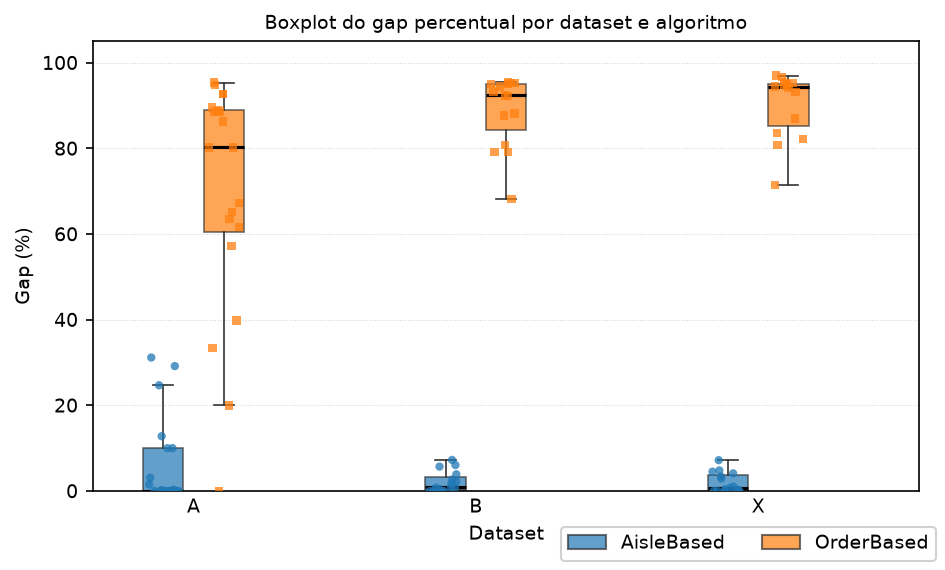

Figura 1 salva: /home/vinicius/Documents/CEFET/TCC/pfc2/notebooks/experimentos/output/construtivas_final/fig_1.pdf
               /home/vinicius/Documents/CEFET/TCC/pfc2/notebooks/experimentos/output/construtivas_final/fig_1.png


In [10]:
import matplotlib.patches as mpatches

rng1 = np.random.default_rng(SEED)

fig1, ax1 = plt.subplots(figsize=(FIG_W, FIG_H1))

_box_data      = []
_box_pos       = []
_box_colors    = []
_point_data    = []
_point_pos     = []
_point_colors  = []
_point_markers = []
_group_centers = []

_gap_w = 0.30   # espaçamento entre algoritmos dentro de cada dataset
_sep_w = 0.80   # espaçamento entre blocos de dataset

pos = 0.0
for ds in DATASETS:
    _center_start = pos
    for algo in ALGOS:
        _sub = df_inst[
            (df_inst["dataset"] == ds) & (df_inst["algo_id"] == algo)
        ]["gap"].dropna().values
        _box_data.append(_sub)
        _box_pos.append(pos)
        _box_colors.append(COLORS[algo])
        jitter = rng1.uniform(-0.08, 0.08, size=len(_sub))
        _point_data.extend(_sub)
        _point_pos.extend([pos + j_ for j_ in jitter])
        _point_colors.extend([COLORS[algo]] * len(_sub))
        _point_markers.extend([MARKERS[algo]] * len(_sub))
        pos += _gap_w
    _group_centers.append((_center_start + pos - _gap_w) / 2)
    pos += _sep_w

# Boxplot preenchido com as cores padrão por algoritmo
bp = ax1.boxplot(
    _box_data, positions=_box_pos,
    widths=0.20,
    patch_artist=True,
    showfliers=False,
    medianprops=dict(color="black", linewidth=1.5),
    whiskerprops=dict(linewidth=0.8, color="#333333"),
    capprops=dict(linewidth=0.8, color="#333333"),
    boxprops=dict(linewidth=0.8, edgecolor="#333333"),
)

for patch, color in zip(bp["boxes"], _box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.70)

# Pontos individuais sobre as caixas com cores e marcadores distintos
for _x, _y, _c, _m in zip(_point_pos, _point_data, _point_colors, _point_markers):
    ax1.scatter(_x, _y, color=_c, marker=_m, s=16, alpha=0.75, edgecolors="none", zorder=3)

# Escala simétrica-logarítmica com limiar 1, divisão perfeitamente igual em cada tick (linscale=0.9, base=10)
# Ticks: 0, 1, 10, 100 (cada intervalo corresponde a exatamente 1 unidade de transformação na tela)
# ax1.set_yscale("symlog", linthresh=1, linscale=0.9, base=10)
ax1.set_ylim(bottom=0.0, top=105.0)
ax1.set_ylabel("Gap (%)")

# _yticks = [0, 1, 10, 100]
# ax1.set_yticks(_yticks)
# ax1.set_yticklabels([fmt(t, 0) for t in _yticks])

ax1.set_xticks(_group_centers)
ax1.set_xticklabels([DS_LABELS[ds] for ds in DATASETS])
ax1.set_xlim(-0.35, pos - _sep_w + 0.35)
ax1.set_xlabel("Dataset")

# Legenda diferenciada por algoritmo com cores padrão
_patches = [
    mpatches.Patch(facecolor=COLORS[a], edgecolor="#333333", alpha=0.70, label=ALGO_LABELS[a])
    for a in ALGOS
]
# ax1.legend(handles=_patches, loc="center right", framealpha=0.9)
ax1.grid(axis="y", linestyle=":", linewidth=0.5, alpha=0.5)
ax1.tick_params(axis="x", which="both", length=0)

ax1.set_title("Boxplot do gap percentual por dataset e algoritmo")

fig1.legend(
    handles=_patches,
    loc="outside lower right",   # reservado pelo constrained layout
    ncol=len(ALGOS),
    framealpha=0.9,
)

fig1.tight_layout()
_fig1_pdf = OUTPUT_DIR / "fig_1.pdf"
_fig1_png = OUTPUT_DIR / "fig_1.png"
fig1.savefig(_fig1_pdf, bbox_inches="tight")
fig1.savefig(_fig1_png, bbox_inches="tight", dpi=300)
display(fig1)
plt.close(fig1)
print("Figura 1 salva:", _fig1_pdf)
print("              ", _fig1_png)



## 10. Figura 2: Unidades e Corredores

**Objetivo:** Evidenciar o mecanismo da disparidade de qualidade entre as construtivas através de dois painéis em escala logarítmica:
* **Painel Esquerdo (Unidades selecionadas):** Quantidade total de unidades coletadas na onda.
* **Painel Direito (Corredores visitados):** Quantidade total de corredores de estoque visitados para atender a onda.
* **Cores e Marcadores (diferenciação por algoritmo):**
  * **AisleBased:** Azul padrão (`tab:blue`), marcador circular (`o`).
  * **OrderBased:** Laranja padrão (`tab:orange`), marcador quadrado (`s`).


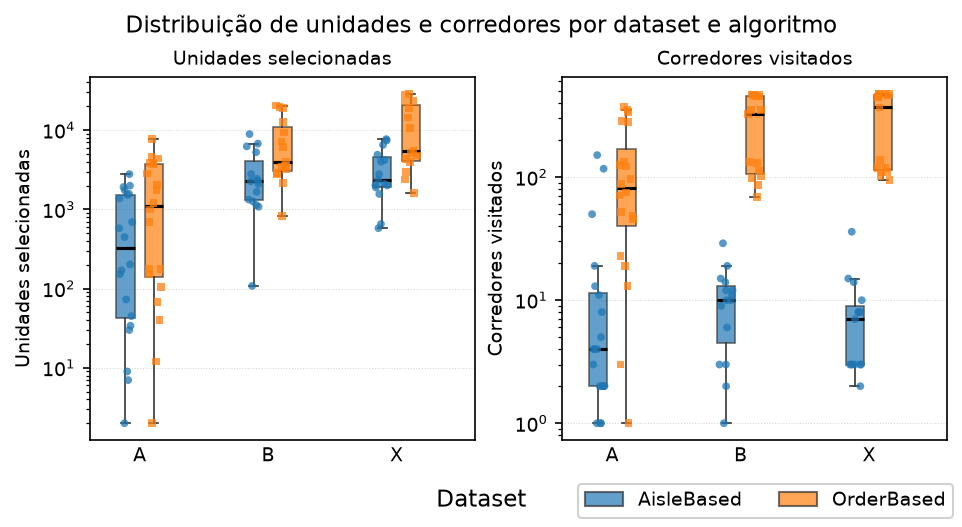

Figura 2 salva: /home/vinicius/Documents/CEFET/TCC/pfc2/notebooks/experimentos/output/construtivas_final/fig_2.pdf
               /home/vinicius/Documents/CEFET/TCC/pfc2/notebooks/experimentos/output/construtivas_final/fig_2.png


In [11]:
rng2 = np.random.default_rng(SEED)

# layout="constrained" substitui o tight_layout e reserva espaço para suptitle/legenda
fig2, (ax_left, ax_right) = plt.subplots(
    1, 2, figsize=(FIG_W, FIG_H2), layout="constrained"
)

fig2.suptitle("Distribuição de unidades e corredores por dataset e algoritmo")
fig2.supxlabel("Dataset")

for ax, col, ylabel, title in [
    (ax_left,  "items",  "Unidades selecionadas", "Unidades selecionadas"),
    (ax_right, "aisles", "Corredores visitados",  "Corredores visitados"),
]:
    _box_data2   = []
    _box_pos2    = []
    _box_colors2 = []
    _pt_data2    = []
    _pt_pos2     = []
    _pt_colors2  = []
    _pt_markers2 = []
    _group_ctrs2 = []

    pos2 = 0.0
    _gap2 = 0.28
    _sep2 = 0.70

    for ds in DATASETS:
        _cstart = pos2
        for algo in ALGOS:
            _sub2 = df_inst[(df_inst["dataset"] == ds) & (df_inst["algo_id"] == algo)][col].dropna().values
            _box_data2.append(_sub2)
            _box_pos2.append(pos2)
            _box_colors2.append(COLORS[algo])
            jitter2 = rng2.uniform(-0.07, 0.07, size=len(_sub2))
            _pt_data2.extend(_sub2)
            _pt_pos2.extend([pos2 + j_ for j_ in jitter2])
            _pt_colors2.extend([COLORS[algo]] * len(_sub2))
            _pt_markers2.extend([MARKERS[algo]] * len(_sub2))
            pos2 += _gap2
        _group_ctrs2.append((_cstart + pos2 - _gap2) / 2)
        pos2 += _sep2

    bp2 = ax.boxplot(
        _box_data2, positions=_box_pos2,
        widths=0.18,
        patch_artist=True,
        showfliers=False,
        medianprops=dict(color="black", linewidth=1.5),
        whiskerprops=dict(linewidth=0.8, color="#333333"),
        capprops=dict(linewidth=0.8, color="#333333"),
        boxprops=dict(linewidth=0.8, edgecolor="#333333"),
    )
    for patch, color in zip(bp2["boxes"], _box_colors2):
        patch.set_facecolor(color)
        patch.set_alpha(0.70)

    for _x2, _y2, _c2, _m2 in zip(_pt_pos2, _pt_data2, _pt_colors2, _pt_markers2):
        ax.scatter(_x2, _y2, color=_c2, marker=_m2, s=14, alpha=0.75, edgecolors="none", zorder=3)

    ax.set_yscale("log")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks(_group_ctrs2)
    ax.set_xticklabels([DS_LABELS[ds] for ds in DATASETS])
    ax.set_xlim(-0.35, pos2 - _sep2 + 0.35)
    ax.grid(axis="y", linestyle=":", linewidth=0.5, alpha=0.5)
    ax.tick_params(axis="x", which="both", length=0)

# Legenda unificada: fica na parte inferior, abaixo do supxlabel,
# sem competir com o suptitle no topo
_patches2 = [
    mpatches.Patch(facecolor=COLORS[a], alpha=0.70, edgecolor="#333333", label=ALGO_LABELS[a])
    for a in ALGOS
]
fig2.legend(
    handles=_patches2,
    loc="outside lower right",   # reservado pelo constrained layout
    ncol=len(ALGOS),
    framealpha=0.9,
)

_fig2_pdf = OUTPUT_DIR / "fig_2.pdf"
_fig2_png = OUTPUT_DIR / "fig_2.png"
fig2.savefig(_fig2_pdf, bbox_inches="tight")
fig2.savefig(_fig2_png, bbox_inches="tight", dpi=300)
display(fig2)
plt.close(fig2)
print("Figura 2 salva:", _fig2_pdf)
print("              ", _fig2_png)

## 11. Tabela 4: Piores Instâncias do AisleBased no Dataset A

**Objetivo:** Caracterizar a cauda de desempenho do `AisleBased` no dataset A, inspecionando as 5 instâncias com maior gap relativo e comparando a composição da solução obtida com a Melhor Solução Conhecida (MSC) para diagnosticar se o excesso está em corredores ou unidades.

### Legenda e Descrição das Colunas
* **Instância:** Identificador numérico da instância no dataset `A` (ordenadas de forma decrescente pelo gap relativo do $AisleBased$).
* **Gap (%):** Gap relativo percentual da solução do $AisleBased$ em relação à MSC da respectiva instância ($\frac{\text{MSC} - \text{Obj}}{\text{MSC}} \times 100$).
* **Un.:** Quantidade total de unidades de itens coletadas na solução do $AisleBased$.
* **Corr.:** Quantidade total de corredores de estoque visitados na solução do $AisleBased$.
* **Un. MSC:** Quantidade total de unidades de itens coletadas na Melhor Solução Conhecida (MSC) para essa instância.
* **Corr. MSC:** Quantidade total de corredores de estoque visitados na Melhor Solução Conhecida (MSC) para essa instância.


In [ ]:
_ds_a_aisle = df_inst[
    (df_inst["dataset"] == "a") & (df_inst["algo_id"] == "aisle_based")
].copy().sort_values("gap", ascending=False)

top5 = _ds_a_aisle.head(5).copy()

HEADER_4 = [["Instância", ("Gap (%)", False), "Un.", "Corr.", "Un. MSC", "Corr. MSC"]]

tab4_rows_csv = []
tab4_rows_tex = []

for _, row in top5.iterrows():
    _d_items  = row["items"]  - row["msc_items"]
    _d_aisles = row["aisles"] - row["msc_aisles"]

    if _d_aisles > TOL and abs(_d_items) <= TOL:
        excesso = "excesso exclusivamente em corredores visitados"
    elif abs(_d_aisles) <= TOL and _d_items < -TOL:
        excesso = "déficit em unidades selecionadas"
    elif _d_aisles > TOL and _d_items < -TOL:
        excesso = "excesso em corredores visitados e déficit em unidades selecionadas"
    elif _d_aisles > TOL and _d_items > TOL:
        excesso = "excesso em corredores e em unidades"
    else:
        excesso = f"variação: diff_unidades={_d_items:.1f}, diff_corredores={_d_aisles:.1f}"

    print(f"Instância {row['instance']}: {excesso} (obtido: {row['items']:.0f} un / {row['aisles']:.0f} corr; MSC: {row['msc_items']:.0f} un / {row['msc_aisles']:.0f} corr)")

    tab4_rows_csv.append([
        row["instance"], row["gap"], row["items"], row["aisles"],
        row["msc_items"], row["msc_aisles"]
    ])
    tab4_rows_tex.append([
        row["instance"].replace("instance_", ""),
        fmt(row["gap"]),
        fmt(row["items"], 0),
        fmt(row["aisles"], 0),
        fmt(row["msc_items"], 0),
        fmt(row["msc_aisles"], 0),
    ])

df_tab4 = pd.DataFrame(tab4_rows_csv, columns=[
    "Instancia", "Gap", "Unidades", "Corredores", "MSC_Unidades", "MSC_Corredores"
])
tex4 = make_tabular(HEADER_4, tab4_rows_tex, "lrrrrr")

LEGENDA_TAB4_TEX = """% Legenda e Descrição das Colunas:
% - Instância: Identificador numérico da instância no dataset A (piores 5 do AisleBased).
% - Gap (%): Gap relativo percentual da solução do AisleBased em relação à MSC.
% - Un.: Unidades de itens coletadas na solução do AisleBased.
% - Corr.: Corredores de estoque visitados na solução do AisleBased.
% - Un. MSC: Unidades coletadas na Melhor Solução Conhecida (MSC).
% - Corr. MSC: Corredores visitados na Melhor Solução Conhecida (MSC)."""

tex4_completo = tex4 + "\n\n" + LEGENDA_TAB4_TEX
_csv4, _tex4 = salvar_tabela("tab_4", df_tab4, tex4_completo)

print("\nTabela 4 salva:", _csv4)
print("              ", _tex4)
display(df_tab4)
print("\n--- Conteúdo completo de tab_4.tex ---")
for _ln in tex4_completo.split("\n"):
    print(_ln)

print("\n--- Legenda da Tabela 4 ---")
print("""  * Instância: Identificador da instância no dataset A (piores 5 do AisleBased).
  * Gap (%): Gap relativo percentual em relação à MSC.
  * Un.: Unidades coletadas pelo AisleBased.
  * Corr.: Corredores visitados pelo AisleBased.
  * Un. MSC: Unidades coletadas na Melhor Solução Conhecida (MSC).
  * Corr. MSC: Corredores visitados na Melhor Solução Conhecida (MSC).""")

# CSV complementar com tamanho das instâncias (não vai para o texto principal)
_ds_a_all = df_inst[
    (df_inst["dataset"] == "a") & (df_inst["algo_id"] == "aisle_based")
].copy()
_piores_idx = set(top5["instance"].values)
_demais     = _ds_a_all[~_ds_a_all["instance"].isin(_piores_idx)]

_comp_piores = top5[["instance", "n_orders", "n_items", "n_aisles_inst", "lb", "ub"]].copy()
_comp_piores["grupo"] = "piores_5"
_comp_demais = pd.DataFrame([{
    "instance": "mediana_demais",
    "n_orders":      _demais["n_orders"].median(),
    "n_items":       _demais["n_items"].median(),
    "n_aisles_inst": _demais["n_aisles_inst"].median(),
    "lb":            _demais["lb"].median(),
    "ub":            _demais["ub"].median(),
    "grupo":         "demais_15"
}])
_comp = pd.concat([_comp_piores, _comp_demais], ignore_index=True)
_comp_path = OUTPUT_DIR / "tab_4_complementar.csv"
_comp.to_csv(_comp_path, index=False)
print("\nCSV complementar salvo:", _comp_path)
display(_comp)


## 12. Apêndice A1: Decomposição em Relação à MSC

**Objetivo:** Quantificar o afastamento estrutural das soluções construtivas em relação à Melhor Solução Conhecida (MSC) e a saturação da capacidade do carrinho/onda ($UB$).

### Legenda e Descrição das Colunas
* **Dataset:** Subconjunto de instâncias avaliado (`A`, `B` e `X`).
* **Algoritmo:** Heurística construtiva avaliada (`AisleBased` ou `OrderBased`).
* **Dif. rel. unidades (%):** Mediana da diferença percentual relativa de unidades coletadas em relação à MSC ($\frac{\text{Unidades} - \text{Unidades}_{\text{MSC}}}{\text{Unidades}_{\text{MSC}}} \times 100$). Valores positivos indicam que o método selecionou mais unidades que a melhor solução conhecida; negativos indicam déficit de unidades.
* **Dif. rel. corredores (%):** Mediana da diferença percentual relativa de corredores visitados em relação à MSC ($\frac{\text{Corredores} - \text{Corredores}_{\text{MSC}}}{\text{Corredores}_{\text{MSC}}} \times 100$). Valores positivos representam sobrecusto de corredores visitados em comparação com a MSC.
* **Unidades/UB (%):** Mediana da taxa de utilização do limite superior de capacidade ($UB$) da instância ($\frac{\text{Unidades}}{UB} \times 100$). Indica o quanto a onda formada preencheu a capacidade disponível no separador.


In [ ]:
tabA1_rows_csv = []
tabA1_rows_tex = []

HEADER_A1 = [[
    "Dataset", "Algoritmo",
    ("Dif. rel. unidades (%)", False),
    ("Dif. rel. corredores (%)", False),
    "Unidades/UB (mediana)",
]]

for ds in DATASETS:
    ds_label = DS_LABELS[ds]
    for i, algo in enumerate(ALGOS):
        _sub = df_inst[(df_inst["dataset"] == ds) & (df_inst["algo_id"] == algo)].copy()

        _dif_items  = ((_sub["items"] - _sub["msc_items"]) / _sub["msc_items"] * 100.0).dropna()
        _dif_aisles = ((_sub["aisles"] - _sub["msc_aisles"]) / _sub["msc_aisles"] * 100.0).dropna()
        _units_ub   = (_sub["items"] / _sub["ub"]).dropna()

        med_dif_items  = _dif_items.median()
        med_dif_aisles = _dif_aisles.median()
        med_units_ub   = _units_ub.median()

        tabA1_rows_csv.append([
            ds_label, ALGO_LABELS[algo],
            med_dif_items, med_dif_aisles, med_units_ub
        ])
        tabA1_rows_tex.append([
            ds_label if i == 0 else "",
            ALGO_LABELS[algo],
            fmt(med_dif_items),
            fmt(med_dif_aisles),
            fmt(med_units_ub, 3),
        ])

df_tabA1 = pd.DataFrame(tabA1_rows_csv, columns=[
    "Dataset", "Algoritmo", "Dif_rel_unidades_pct",
    "Dif_rel_corredores_pct", "Unidades_UB"
])
texA1 = make_tabular(HEADER_A1, tabA1_rows_tex, "llrrr")

LEGENDA_TABA1_TEX = """% Legenda e Descrição das Colunas:
% - Dataset: Subconjunto de instâncias avaliado (A, B, X).
% - Algoritmo: Heurística construtiva avaliada (AisleBased ou OrderBased).
% - Dif. rel. unidades (%): Mediana da diferença percentual relativa de unidades em relação à MSC.
% - Dif. rel. corredores (%): Mediana da diferença percentual relativa de corredores visitados em relação à MSC.
% - Unidades/UB: Mediana da fração de ocupação de capacidade em relação ao UB da instância."""

texA1_completo = texA1 + "\n\n" + LEGENDA_TABA1_TEX
_csvA1, _texA1 = salvar_tabela("tab_A1", df_tabA1, texA1_completo)

print("Tabela A1 salva:", _csvA1)
print("               ", _texA1)
print()
display(df_tabA1)
print()
print("--- Conteúdo completo de tab_A1.tex ---")
for _ln in texA1_completo.split("\n"):
    print(_ln)

print("\n--- Legenda da Tabela A1 ---")
print("""  * Dataset: Subconjunto de instâncias avaliado (A, B, X).
  * Algoritmo: Heurística construtiva avaliada (AisleBased ou OrderBased).
  * Dif. rel. unidades (%): Mediana da diferença percentual de unidades vs. MSC.
  * Dif. rel. corredores (%): Mediana da diferença percentual de corredores vs. MSC.
  * Unidades/UB: Mediana da fração de unidades sobre o limite superior (capacidade) da instância.""")


## 13. Apêndice A2: Resultados Detalhados por Instância

**Objetivo:** Apresentar a desagregação completa dos resultados obtidos por ambas as construtivas para todas as 50 instâncias avaliadas no formato de tabela longa (`longtable`).

### Legenda e Descrição das Colunas
* **Dataset/Instância:** Identificador composto da instância no formato `Dataset/Instância` (ex.: `A/0001`, `B/0010`, `X/0015`).
* **Gap Aisle:** Gap relativo percentual (%) da solução do $AisleBased$ em relação à MSC daquela instância.
* **Gap Order:** Gap relativo percentual (%) da solução do $OrderBased$ em relação à MSC daquela instância.
* **Unid. Aisle:** Quantidade total de unidades de itens coletadas na solução do $AisleBased$.
* **Unid. Order:** Quantidade total de unidades de itens coletadas na solução do $OrderBased$.
* **Corr. Aisle:** Quantidade total de corredores de estoque visitados na solução do $AisleBased$.
* **Corr. Order:** Quantidade total de corredores de estoque visitados na solução do $OrderBased$.


In [ ]:
# Pivotar para ter uma linha por instância
_pivot_inst = df_inst.pivot_table(
    index=["dataset", "instance"],
    columns="algo_id",
    values=["gap", "items", "aisles"],
    aggfunc="first"
).reset_index()
_pivot_inst.columns = [
    f"{col[0]}_{col[1]}" if col[1] else col[0]
    for col in _pivot_inst.columns
]
_pivot_inst = _pivot_inst.sort_values(["dataset", "instance"])
_pivot_inst["ds_inst"] = (
    _pivot_inst["dataset"].map(DS_LABELS) + "/" +
    _pivot_inst["instance"].str.replace("instance_", "", regex=False)
)
df_tabA2 = _pivot_inst[[
    "ds_inst",
    "gap_aisle_based", "gap_order_based",
    "items_aisle_based", "items_order_based",
    "aisles_aisle_based", "aisles_order_based",
]].copy()
df_tabA2.columns = [
    "Dataset/Instância",
    "Gap Aisle", "Gap Order",
    "Unid. Aisle", "Unid. Order",
    "Corr. Aisle", "Corr. Order",
]
_csvA2 = OUTPUT_DIR / "tab_A2.csv"
df_tabA2.to_csv(_csvA2, index=False)
# .tex em ambiente longtable com cabeçalho repetido entre páginas
_hdr_a2 = (
    "Dataset/Instância & Gap Aisle & Gap Order & "
    "Unid. Aisle & Unid. Order & Corr. Aisle & Corr. Order"
)
_tex_lines_A2 = []
_tex_lines_A2.append(r"\small")
_tex_lines_A2.append(r"\begin{longtable}{lrrrrrr}")
_tex_lines_A2.append(r"\toprule")
_tex_lines_A2.append(_hdr_a2 + r" \\")
_tex_lines_A2.append(r"\midrule")
_tex_lines_A2.append(r"\endfirsthead")
_tex_lines_A2.append(r"\toprule")
_tex_lines_A2.append(_hdr_a2 + r" \\")
_tex_lines_A2.append(r"\midrule")
_tex_lines_A2.append(r"\endhead")
_tex_lines_A2.append(r"\midrule")
_tex_lines_A2.append(r"\multicolumn{7}{r}{\textit{(continua)}} \\")
_tex_lines_A2.append(r"\endfoot")
_tex_lines_A2.append(r"\bottomrule")
_tex_lines_A2.append(r"\endlastfoot")
for _, row in df_tabA2.iterrows():
    inst_tex = tex_escape(row["Dataset/Instância"])
    line = (
        f"{inst_tex} & "
        f"{fmt(row['Gap Aisle'])} & {fmt(row['Gap Order'])} & "
        f"{fmt(row['Unid. Aisle'], 0)} & {fmt(row['Unid. Order'], 0)} & "
        f"{fmt(row['Corr. Aisle'], 0)} & {fmt(row['Corr. Order'], 0)} \\\\"
    )
    _tex_lines_A2.append(line)
_tex_lines_A2.append(r"\end{longtable}")
LEGENDA_TABA2_TEX = """% Legenda e Descrição das Colunas:
% - Dataset/Instância: Identificador no formato Dataset/Instância.
% - Gap Aisle: Gap relativo percentual (%) do AisleBased em relação à MSC.
% - Gap Order: Gap relativo percentual (%) do OrderBased em relação à MSC.
% - Unid. Aisle: Unidades coletadas pelo AisleBased.
% - Unid. Order: Unidades coletadas pelo OrderBased.
% - Corr. Aisle: Corredores visitados pelo AisleBased.
% - Corr. Order: Corredores visitados pelo OrderBased."""
_texA2_str = "\n".join(_tex_lines_A2) + "\n\n" + LEGENDA_TABA2_TEX
_texA2_path = OUTPUT_DIR / "tab_A2.tex"
_texA2_path.write_text(_texA2_str, encoding="utf-8")
print("Tabela A2 salva:", _csvA2)
print("               ", _texA2_path)
print()
print("\n--- Tabela A2 completa (50 instâncias) ---")
with pd.option_context("display.max_rows", 100):
    display(df_tabA2)
print("\n--- Conteúdo completo de tab_A2.tex (longtable) ---")
for _ln in _texA2_str.split("\n"):
    print(_ln)
print("\n--- Legenda da Tabela A2 ---")
print("""  * Dataset/Instância: Identificador da instância (A/0001 a X/0015).
  * Gap Aisle: Gap relativo (%) da solução do AisleBased.
  * Gap Order: Gap relativo (%) da solução do OrderBased.
  * Unid. Aisle: Quantidade de unidades coletadas na onda do AisleBased.
  * Unid. Order: Quantidade de unidades coletadas na onda do OrderBased.
  * Corr. Aisle: Quantidade de corredores visitados pelo AisleBased.
  * Corr. Order: Quantidade de corredores visitados pelo OrderBased.""")


## 14. Números-Chave para o Texto

**Objetivo:** Reunir e documentar de forma centralizada os valores estatísticos e métricas consolidadas citadas ao longo da monografia.

### Legenda e Descrição das Chaves (`numeros_chave.csv`)
* `VED_geral`: Placar global de Vitórias--Empates--Derrotas do $AisleBased$ contra o $OrderBased$ em gap de objetivo considerando as 50 instâncias (`49--1--0`).
* `pvalor_geral`: p-valor bilateral exato do Teste de Sinais sobre todas as 50 instâncias ($3{,}55 \cdot 10^{-15}$), confirmando significância estatística extrema.
* `gap_le1pct_aisle_based`: Fração de instâncias em que o $AisleBased$ atingiu $\text{gap} \le 1{,}0\%$ (`28/50`, 56%).
* `gap_le1pct_order_based`: Fração de instâncias em que o $OrderBased$ atingiu $\text{gap} \le 1{,}0\%$ (`1/50`, 2%).
* `gap_mediano_aisle_based`: Gap relativo mediano global do $AisleBased$ ($0{,}73\%$).
* `gap_p90_aisle_based`: 90º percentil de gap global do $AisleBased$ ($10{,}00\%$).
* `gap_mediano_order_based`: Gap relativo mediano global do $OrderBased$ ($88{,}75\%$).
* `gap_p90_order_based`: 90º percentil de gap global do $OrderBased$ ($95{,}35\%$).
* `razao_unidades_{A,B,X}`: Razão entre as medianas de unidades coletadas ($OrderBased / AisleBased$) para cada dataset ($3{,}40$ em A; $1{,}76$ em B; $2{,}33$ em X).
* `razao_corredores_{A,B,X}`: Razão entre as medianas de corredores visitados ($OrderBased / AisleBased$) para cada dataset ($20{,}38$ em A; $32{,}70$ em B; $52{,}57$ em X).
* `razao_tempo_mediana_{A,B,X}`: Razão mediana dos tempos de execução pareados ($OrderBased / AisleBased$) em cada dataset ($19{,}04$ em A; $16{,}44$ em B; $3{,}65$ em X).
* `n_gaps_negativos`: Número de instâncias com gap negativo (solução superior à MSC registrada). Valor esperado: `0`.
* `n_instancias_ambos_igualam_msc`: Quantidade de instâncias em que ambos os algoritmos empataram exatamente com a MSC ($	ext{gap} = 0$).


In [ ]:
numeros = []

def add_num(rotulo, valor):
    numeros.append({"rotulo": rotulo, "valor": valor})

_geral_aisle = df_inst[df_inst["algo_id"] == "aisle_based"].set_index("instance")
_geral_order = df_inst[df_inst["algo_id"] == "order_based"].set_index("instance")
_common_geral = _geral_aisle.index.intersection(_geral_order.index)
_ga = _geral_aisle.loc[_common_geral, "gap"].values
_go = _geral_order.loc[_common_geral, "gap"].values
_w, _t, _l, _dg = resumo_pareado(_ga, _go, maior_e_melhor_a=False)
_pv = teste_sinais(_go - _ga)
add_num("VED_geral", f"{_w}--{_t}--{_l}")
add_num("pvalor_geral", f"{_pv:.4e}")

for algo in ALGOS:
    _sub = df_inst[df_inst["algo_id"] == algo]["gap"].dropna()
    _frac = (_sub <= 1.0 + TOL).sum()
    add_num(f"gap_le1pct_{algo}", f"{_frac}/{len(_sub)}")

for algo in ALGOS:
    _sub = df_inst[df_inst["algo_id"] == algo]["gap"].dropna()
    add_num(f"gap_mediano_{algo}", f"{_sub.median():.4f}")
    add_num(f"gap_p90_{algo}",     f"{_sub.quantile(0.90):.4f}")

for ds in DATASETS:
    _a = df_inst[(df_inst["dataset"] == ds) & (df_inst["algo_id"] == "aisle_based")]
    _o = df_inst[(df_inst["dataset"] == ds) & (df_inst["algo_id"] == "order_based")]
    add_num(f"razao_unidades_{DS_LABELS[ds]}",
            f"{np.median(_o['items'].values) / np.median(_a['items'].values):.4f}")
    add_num(f"razao_corredores_{DS_LABELS[ds]}",
            f"{np.median(_o['aisles'].values) / np.median(_a['aisles'].values):.4f}")

for ds in DATASETS:
    _ta = df_inst[(df_inst["dataset"] == ds) & (df_inst["algo_id"] == "aisle_based")]["tempo_s"].values
    _to = df_inst[(df_inst["dataset"] == ds) & (df_inst["algo_id"] == "order_based")]["tempo_s"].values
    _r  = _to / np.where(_ta > 0, _ta, np.nan)
    add_num(f"razao_tempo_mediana_{DS_LABELS[ds]}", f"{np.nanmedian(_r):.4f}")

_neg = (df_inst["gap"] < -TOL).sum()
add_num("n_gaps_negativos", str(_neg))

_eq_msc = df_inst[np.abs(df_inst["gap"]) <= TOL]
_eq_inst = _eq_msc.groupby(["dataset", "instance"]).filter(
    lambda g: len(g) == 2
)
add_num("n_instancias_ambos_igualam_msc", str(len(_eq_inst) // 2))

df_numeros = pd.DataFrame(numeros)
_num_path = OUTPUT_DIR / "numeros_chave.csv"
df_numeros.to_csv(_num_path, index=False)
print("Números-chave salvos:", _num_path)
print()
with pd.option_context("display.max_rows", 50):
    display(df_numeros)


## 15. Verificações Finais e Inventário

Executa todas as 38 checagens automatizadas de conformidade estrutural, reprodução numérica dos gaps médios de referência e inventário dos arquivos gerados.

In [ ]:
_checks = []

def check(nome, condicao, detalhe=""):
    status = "ok" if condicao else "FALHA"
    _checks.append({"verificação": nome, "status": status, "detalhe": detalhe})
    if not condicao:
        print(f"FALHA: {nome} — {detalhe}")

# 1. 50 instâncias por algoritmo
for algo in ALGOS:
    n = len(df_inst[df_inst["algo_id"] == algo])
    check(f"50 instâncias — {ALGO_LABELS[algo]}", n == 50, f"encontrado {n}")

# 2. Sem ausentes nas métricas principais
for col in ["gap", "objective", "items", "aisles", "tempo_s"]:
    n_na = df_inst[col].isna().sum()
    check(f"sem ausentes — {col}", n_na == 0, f"{n_na} ausente(s)")

# 3. V+E+D = N por dataset
for ds in DATASETS:
    _df_sub = df_inst[df_inst["dataset"] == ds]
    _a = _df_sub[_df_sub["algo_id"] == "aisle_based"].set_index("instance")
    _o = _df_sub[_df_sub["algo_id"] == "order_based"].set_index("instance")
    _c = _a.index.intersection(_o.index)
    _w, _t, _l, _ = resumo_pareado(_a.loc[_c, "gap"].values, _o.loc[_c, "gap"].values)
    check(f"V+E+D = N — {DS_LABELS[ds]}", _w + _t + _l == len(_c),
          f"{_w}+{_t}+{_l}={_w+_t+_l}, N={len(_c)}")

# 4. Reprodução dos valores de referência com tolerância 1e-6
_REF_GAPS = {
    ("aisle_based", "a"): 6.149314,
    ("aisle_based", "b"): 2.159742,
    ("aisle_based", "x"): 1.978697,
    ("order_based",  "a"): 69.304408,
    ("order_based",  "b"): 88.754368,
    ("order_based",  "x"): 90.398695,
}
for (algo, ds), ref in _REF_GAPS.items():
    val = df_inst[(df_inst["algo_id"] == algo) & (df_inst["dataset"] == ds)]["gap"].mean()
    check(f"gap médio ref — {ALGO_LABELS[algo]}/{DS_LABELS[ds]}",
          abs(val - ref) <= 1e-6, f"obtido={val:.6f}, ref={ref:.6f}")

# 5. V–E–D geral 49-1-0 e p-valor geral ≈ 3.55e-15
_geral_a2 = df_inst[df_inst["algo_id"] == "aisle_based"].set_index("instance")
_geral_o2 = df_inst[df_inst["algo_id"] == "order_based"].set_index("instance")
_c2 = _geral_a2.index.intersection(_geral_o2.index)
_w2, _t2, _l2, _ = resumo_pareado(
    _geral_a2.loc[_c2, "gap"].values, _geral_o2.loc[_c2, "gap"].values
)
_pv2 = teste_sinais(_geral_o2.loc[_c2, "gap"].values - _geral_a2.loc[_c2, "gap"].values)
check("V–E–D geral 49-1-0", _w2 == 49 and _t2 == 1 and _l2 == 0,
      f"obtido {_w2}–{_t2}–{_l2}")
check("p-valor geral ≈ 3,55e-15", abs(_pv2 - 3.55e-15) <= 1e-16 * 1000 or _pv2 < 1e-14,
      f"obtido {_pv2:.4e}")

# 6. Checagem estrutural dos .tex
for _tex_file in sorted(OUTPUT_DIR.glob("*.tex")):
    _content = _tex_file.read_text(encoding="utf-8")
    _errs = verificar_tex(_content, _tex_file.name)
    check(f"estrutura .tex — {_tex_file.name}", len(_errs) == 0, "; ".join(_errs))

# 7. Limites de tamanho (colunas e linhas nas tabelas do corpo)
_EXPECTED_MAX_COLS = {
    "tab_1": 8,
    "tab_2": 5,
    "tab_3": 6,
    "tab_3a": 6,
    "tab_3b": 4,
    "tab_4": 6,
}
_EXPECTED_MAX_ROWS = {
    "tab_1": 8,
    "tab_2": 4,
    "tab_3": 8,
    "tab_3a": 8,
    "tab_3b": 4,
    "tab_4": 5,
}

for _tname in ["tab_1", "tab_2", "tab_3", "tab_3a", "tab_3b", "tab_4"]:
    _tpath = OUTPUT_DIR / f"{_tname}.tex"
    if not _tpath.exists():
        continue
    _tex_content = _tpath.read_text(encoding="utf-8")
    _m_tab = re.search(r'\\begin\{tabular\}\{([a-zA-Z]+)\}', _tex_content)
    if _m_tab:
        n_cols_tex = len(_m_tab.group(1))
        check(f"limite .tex colunas ≤ {_EXPECTED_MAX_COLS[_tname]} — {_tname}",
              n_cols_tex <= _EXPECTED_MAX_COLS[_tname], f"{n_cols_tex} colunas")
    _lines_tex = [l for l in _tex_content.splitlines() if l.strip().endswith(chr(92)*2) and "&" in l]
    _n_data_rows = len(_lines_tex) - 1
    check(f"limite .tex linhas ≤ {_EXPECTED_MAX_ROWS[_tname]} — {_tname}",
          _n_data_rows <= _EXPECTED_MAX_ROWS[_tname], f"{_n_data_rows} linhas")

df_checks = pd.DataFrame(_checks)
n_ok   = (df_checks["status"] == "ok").sum()
n_fail = (df_checks["status"] == "FALHA").sum()
print(f"\nVerificações: {n_ok} ok, {n_fail} falha(s).")
display(df_checks)

if n_fail > 0:
    raise AssertionError(f"Falha em {n_fail} verificação(ões)!")

# Inventário dos arquivos gerados
print("\n=== Inventário de arquivos gerados ===")
_inventory = []
for _f in sorted(OUTPUT_DIR.iterdir()):
    if _f.is_file():
        _size = _f.stat().st_size
        if _f.suffix == ".csv":
            _df_f = pd.read_csv(_f)
            _dim  = f"{len(_df_f)} linhas × {len(_df_f.columns)} colunas"
        else:
            _dim = ""
        _inventory.append({"arquivo": _f.name, "tamanho (bytes)": _size, "dimensões": _dim})
        print(f"  {_f.name:35s}  {_size:8d} bytes  {_dim}")
